In [172]:
import pandas as pd 
import tensorflow as tf
import matplotlib.pyplot as plt
import os, sys
import numpy as np
from scipy.io import loadmat
from datetime import datetime



In [38]:
os.listdir(os.path.join(data_dir, age_dirs[0]))

['nm0861361_rm575703808_1969-11-20_2004.jpg',
 'nm0694361_rm3713568512_1959-1-22_2010.jpg',
 'nm0115161_rm1289919232_1988-12-7_2004.jpg',
 'nm0166061_rm3965158912_1958-3-17_2005.jpg',
 'nm0143261_rm4154955776_1971-2-9_2005.jpg',
 'nm0000161_rm3223755520_1966-9-2_1998.jpg',
 'nm1053961_rm3229976320_1981-2-2_2010.jpg',
 'nm0092961_rm1859042304_1991-2-28_2011.jpg',
 'nm2088161_rm3051722496_1979-6-5_2008.jpg',
 'nm0092961_rm3483286272_1991-2-28_2008.jpg',
 'nm0252961_rm2453444096_1972-9-6_2007.jpg',
 'nm0861361_rm3628181504_1969-11-20_2011.jpg',
 'nm0022161_rm1086828032_1978-9-22_2012.jpg',
 'nm2628561_rm3499551232_1990-3-30_2015.jpg',
 'nm0005561_rm3737753856_1971-9-21_2003.jpg',
 'nm0005461_rm1745721856_1969-10-3_2004.jpg',
 'nm2448361_rm3056894720_1981-2-2_2010.jpg',
 'nm0000161_rm2997918464_1966-9-2_1998.jpg',
 'nm0627961_rm1883558656_1970-4-2_1987.jpg',
 'nm0001661_rm2002101760_1947-3-6_2011.jpg',
 'nm0000161_rm546222592_1966-9-2_2011.jpg',
 'nm1989961_rm1758771200_1976-3-8_2005.jpg',

In [ ]:
### Data from https://data.vision.ee.ethz.ch/cvl/rrothe/imdb-wiki/

#Create data fram for each file 
data_dir = '../data/imdb_crop'
dirs = [dir for dir in os.listdir(data_dir) if not dir.startswith('.')]
files_dict = dict()
for dir in dirs:
    files_dict[dir] = os.listdir(data_dir + "/" + dir)


files_dict
file_paths = list()
for key, value in files_dict.items():
    for file in value:
        file_paths.append(data_dir + '/' + key +'/' + file)

file_paths

['../data/imdb_crop/61/nm0861361_rm575703808_1969-11-20_2004.jpg',
 '../data/imdb_crop/61/nm0694361_rm3713568512_1959-1-22_2010.jpg',
 '../data/imdb_crop/61/nm0115161_rm1289919232_1988-12-7_2004.jpg',
 '../data/imdb_crop/61/nm0166061_rm3965158912_1958-3-17_2005.jpg',
 '../data/imdb_crop/61/nm0143261_rm4154955776_1971-2-9_2005.jpg',
 '../data/imdb_crop/61/nm0000161_rm3223755520_1966-9-2_1998.jpg',
 '../data/imdb_crop/61/nm1053961_rm3229976320_1981-2-2_2010.jpg',
 '../data/imdb_crop/61/nm0092961_rm1859042304_1991-2-28_2011.jpg',
 '../data/imdb_crop/61/nm2088161_rm3051722496_1979-6-5_2008.jpg',
 '../data/imdb_crop/61/nm0092961_rm3483286272_1991-2-28_2008.jpg',
 '../data/imdb_crop/61/nm0252961_rm2453444096_1972-9-6_2007.jpg',
 '../data/imdb_crop/61/nm0861361_rm3628181504_1969-11-20_2011.jpg',
 '../data/imdb_crop/61/nm0022161_rm1086828032_1978-9-22_2012.jpg',
 '../data/imdb_crop/61/nm2628561_rm3499551232_1990-3-30_2015.jpg',
 '../data/imdb_crop/61/nm0005561_rm3737753856_1971-9-21_2003.jpg',

In [ ]:
#Extract ages from the file names

def file_path_to_age(path: str) -> float:
    """Converts file path to age in years"""
    strings = path.split('/')
    string = strings[-1]
    strs = string.split('_')
    dates = [strs[-2], strs[-1].strip('.jpg')]
    born = [int(value) if int(value) != 0 else 1 for value in dates[0].strip(' ').split('-')]
    photo_taken = int(dates[1])
    days =  datetime(photo_taken, 1, 1)- datetime(*born)
    years = days.days/365.25
    return years

#Create data frame
df = pd.DataFrame()
df['paths'] = file_paths
df['age'] = df.paths.apply(file_path_to_age)
df.head()

,paths,age
0,../data/imdb_crop/61/nm0861361_rm575703808_196...,34.113621
1,../data/imdb_crop/61/nm0694361_rm3713568512_19...,50.943190
2,../data/imdb_crop/61/nm0115161_rm1289919232_19...,15.066393
3,../data/imdb_crop/61/nm0166061_rm3965158912_19...,46.795346
4,../data/imdb_crop/61/nm0143261_rm4154955776_19...,33.894593


In [216]:
df['age_year']= df.age.apply(lambda x: int(round(x)))
df

,paths,age,age_year
0,../data/imdb_crop/61/nm0861361_rm575703808_196...,34.113621,34
1,../data/imdb_crop/61/nm0694361_rm3713568512_19...,50.943190,51
2,../data/imdb_crop/61/nm0115161_rm1289919232_19...,15.066393,15
3,../data/imdb_crop/61/nm0166061_rm3965158912_19...,46.795346,47
4,../data/imdb_crop/61/nm0143261_rm4154955776_19...,33.894593,34
...,...,...,...
460718,../data/imdb_crop/25/nm0794425_rm2834477568_19...,33.070500,33
460719,../data/imdb_crop/25/nm0001525_rm3386808576_19...,41.415469,41
460720,../data/imdb_crop/25/nm0004825_rm722138112_197...,37.059548,37
460721,../data/imdb_crop/25/nm0000325_rm1527027712_19...,45.984942,46


In [264]:
merged_df = pd.merge(df, dfs, on='paths')
merged_df[['age_year', 'age_y']]
merged_df['age_diff'] = merged_df['age_year'] - merged_df.age_y
merged_df.query('age_diff ==0')

/var/folders/lp/thllcq0n66jgk5lvphvj4_1r0000gn/T/ipykernel_98378/2490700023.py:4: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  merged_df.query('age_diff ==0')


,paths,age_x,age_year,dob,photo_taken,full_path,gender,name,face_location,face_score,second_face_score,celeb_names,celeb_id,dob_dt,birth_year,age_y,age_diff
513,../data/imdb_crop/59/nm0000059_rm42126848_1907...,68.613279,69,696659,1976,59/nm0000059_rm42126848_1907-5-22_1976.jpg,1,Laurence Olivier,"[2219.4314711126076, 743.6938237042025, 4427.2...",2.856655,NaN,Andrew Bergman,11559,1907-05-22,1907,69,0
521,../data/imdb_crop/59/nm0000059_rm830656000_190...,68.613279,69,696659,1976,59/nm0000059_rm830656000_1907-5-22_1976.jpg,1,Laurence Olivier,"[1, 1, 3645, 5080]",-inf,NaN,Andrew Dan-Jumbo,11559,1907-05-22,1907,69,0
537,../data/imdb_crop/59/nm0000059_rm3368060160_19...,69.615332,70,696659,1977,59/nm0000059_rm3368060160_1907-5-22_1977.jpg,1,Laurence Olivier,"[211.53645641752854, 316.79318462629277, 526.2...",3.237751,NaN,Andrea Savage,11559,1907-05-22,1907,70,0
539,../data/imdb_crop/59/nm0000059_rm612617728_190...,69.615332,70,696659,1977,59/nm0000059_rm612617728_1907-5-22_1977.jpg,1,Laurence Olivier,"[2872.292165966795, 1097.940634654017, 4094.65...",2.307320,1.859557,Andrew Clarke,11559,1907-05-22,1907,70,0
546,../data/imdb_crop/59/nm0000059_rm914542080_190...,68.613279,69,696659,1976,59/nm0000059_rm914542080_1907-5-22_1976.jpg,1,Laurence Olivier,"[504.4371244585673, 755.1556866878511, 1253.59...",1.689134,NaN,Andrew Dominik,11559,1907-05-22,1907,69,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20016,../data/imdb_crop/22/nm0000022_rm3374955008_19...,59.915127,60,694358,1961,22/nm0000022_rm3374955008_1901-2-1_1961.jpg,1,Clark Gable,"[718.6062752566074, 452.40602798399493, 821.74...",3.220119,3.198253,Al Lewis,3796,1901-02-01,1901,60,0
20017,../data/imdb_crop/22/nm0000022_rm3240737280_19...,59.915127,60,694358,1961,22/nm0000022_rm3240737280_1901-2-1_1961.jpg,1,Clark Gable,"[1, 1, 1023, 1003]",-inf,NaN,Al Lettieri,3796,1901-02-01,1901,60,0
20035,../data/imdb_crop/25/nm0000025_rm2964756480_19...,70.888433,71,704594,2000,25/nm0000025_rm2964756480_1929-2-10_2000.jpg,1,Jerry Goldsmith,"[160.025634261958, 93.57661998614216, 219.2817...",3.951972,2.173866,Alan King,8974,1929-02-10,1929,71,0
20060,../data/imdb_crop/25/nm0000025_rm1304336896_19...,54.888433,55,704594,1984,25/nm0000025_rm1304336896_1929-2-10_1984.jpg,1,Jerry Goldsmith,"[301.6446460729946, 87.81555544218264, 372.221...",3.906306,3.483016,Alan J. Pakula,8974,1929-02-10,1929,55,0


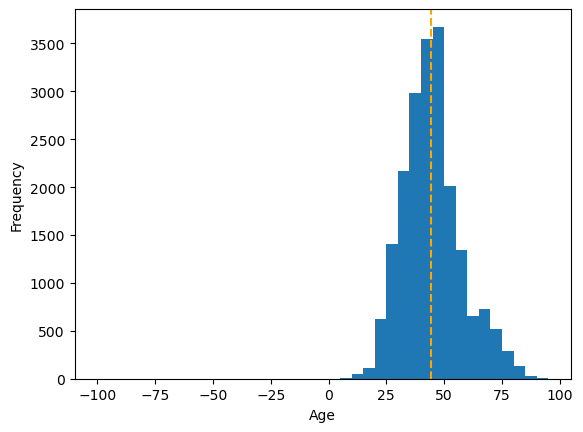

In [245]:
#Age distribution
plt.hist(dfs.age, range=(0,100), bins=range(-100,100, 5))
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.axvline(x=dfs.age.mean(), color = 'orange', linestyle='--', label='Average Age')
plt.legend
plt.show()

In [197]:
import pathlib 
data_dir = '../data/imdb_crop'
data_dir = pathlib.Path(data_dir).with_suffix('')
image_count = len(list(data_dir.glob('*/*.jpg')))
print(image_count)

460723


KeyboardInterrupt: 

In [271]:
df[df.age_year<0].paths

1509      ../data/imdb_crop/61/nm0538261_rm430873088_199...
8321      ../data/imdb_crop/59/nm0206359_rm3020206592_19...
8346      ../data/imdb_crop/59/nm1840659_rm1799859200_19...
8747      ../data/imdb_crop/59/nm0206359_rm2953097728_19...
8755      ../data/imdb_crop/59/nm1840659_rm1355266560_19...
                                ...                        
453754    ../data/imdb_crop/22/nm4478322_rm4056004096_19...
453968    ../data/imdb_crop/22/nm0970122_rm4124083968_19...
455665    ../data/imdb_crop/22/nm1973422_rm811972864_198...
455916    ../data/imdb_crop/22/nm0970122_rm3939534592_19...
456172    ../data/imdb_crop/22/nm0970122_rm4090529536_19...
Name: paths, Length: 531, dtype: object

In [269]:
split_id = int(.8*df.shape[0])
train_X, val_X = df.paths[:split_id], df.paths[split_id:]
train_X

0         ../data/imdb_crop/61/nm0861361_rm575703808_196...
1         ../data/imdb_crop/61/nm0694361_rm3713568512_19...
2         ../data/imdb_crop/61/nm0115161_rm1289919232_19...
3         ../data/imdb_crop/61/nm0166061_rm3965158912_19...
4         ../data/imdb_crop/61/nm0143261_rm4154955776_19...
                                ...                        
368573    ../data/imdb_crop/83/nm0001083_rm4032724992_19...
368574    ../data/imdb_crop/83/nm0005683_rm580813824_194...
368575    ../data/imdb_crop/83/nm0756983_rm3089807616_19...
368576    ../data/imdb_crop/83/nm1087183_rm825667072_197...
368577    ../data/imdb_crop/83/nm0680983_rm459704576_198...
Name: paths, Length: 368578, dtype: object

In [283]:
batch_size = 32
img_height = 224
img_width = 224

split_id = int(.8*df.shape[0])
train_X, val_X = df.paths[:split_id], df.paths[split_id:]
train_y, val_y = df.age[:split_id], df.age[split_id:]

#dataset = tf.data.Dataset.from_tensor_slices((X.values, y.values))

def image_feeder(path:str, age: float) -> any:
    image_bytes = tf.io.read_file(path)
    img = tf.image.decode_jpeg(image_bytes)
    img = tf.image.resize(img, [img_height, img_width])
    img = tf.cast(img, tf.float64)
    return img, age

AUTOTUNE = tf.data.experimental.AUTOTUNE

train_ds = tf.data.Dataset.from_tensor_slices((train_X, train_y))

train_ds = (
    train_ds.map(image_feeder).cache().prefetch(buffer_size=AUTOTUNE)
)

val_ds = tf.data.Dataset.from_tensor_slices((val_X, val_y))

val_ds = (
    val_ds.map(image_feeder).cache().prefetch(buffer_size=AUTOTUNE)
)




In [294]:
IMG_SHAPE = (224,224) + (3,)
base_model = tf.keras.applications.ResNet50(
    include_top=True,
    weights='imagenet',
    input_shape=IMG_SHAPE,
)

2026-01-18 12:28:26.921554: W tensorflow/core/kernels/data/cache_dataset_ops.cc:914] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


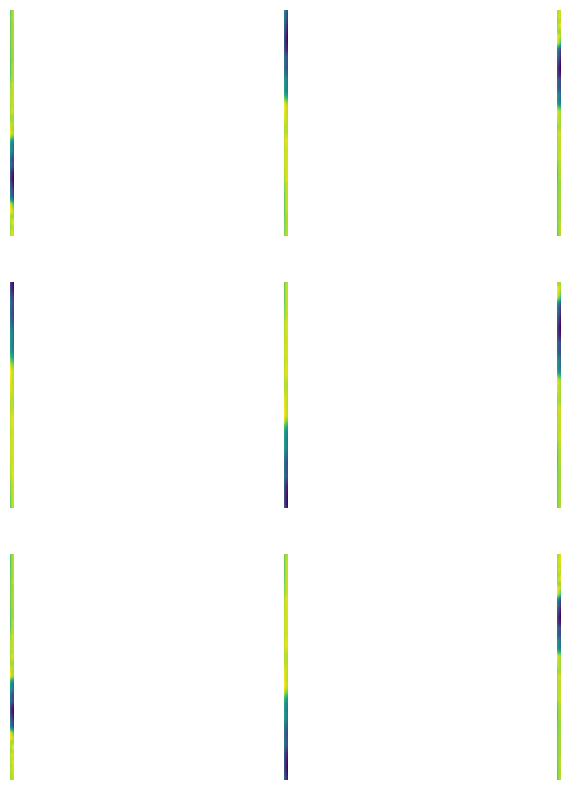

In [279]:

data_augmentation = tf.keras.Sequential([
  tf.keras.layers.RandomFlip('horizontal'),
  tf.keras.layers.RandomRotation(0.2),
])


for image, _ in train_ds.take(1):
  plt.figure(figsize=(10, 10))
  first_image = image[0]
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
    plt.imshow(augmented_image[0] / 255)
    plt.axis('off')

In [282]:
import pathlib 
data_dir = '../data/imdb_crop'
data_dir = pathlib.Path(data_dir).with_suffix('')

batch_size = 32
img_height = 224
img_width = 224

train_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="training",
  seed=11,
  image_size=(img_height, img_width),
  batch_size=batch_size)

val_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="validation",
  seed=11,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 460723 files belonging to 100 classes.
Using 368579 files for training.
Found 460723 files belonging to 100 classes.
Using 92144 files for validation.


AttributeError: '_PrefetchDataset' object has no attribute 'class_names'

2026-01-18 12:47:22.547680: W tensorflow/core/kernels/data/cache_dataset_ops.cc:914] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
2026-01-18 12:47:22.660015: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


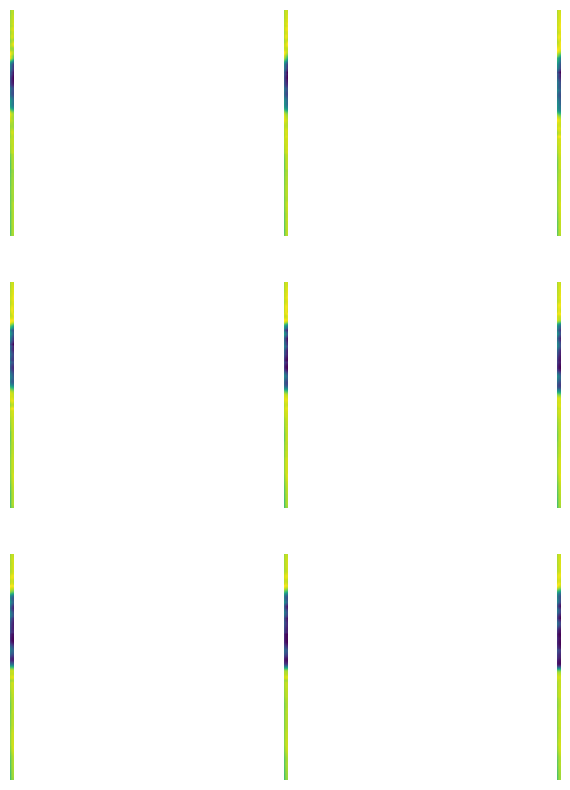

In [286]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    #plt.title(class_names[labels[i]])
    plt.axis("off")

In [306]:
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

In [307]:
rescale = tf.keras.layers.Rescaling(1./127.5, offset=-1)
IMG_SHAPE = (224,224) + (3,)
# Create the base model from the pre-trained model MobileNet V2
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE,
                                               include_top=False,
                                               weights='imagenet')

In [309]:
batch_size = 32
img_height = 224
img_width = 224
AUTOTUNE = tf.data.AUTOTUNE

preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

def image_feeder(path: str, age: float):
    image_bytes = tf.io.read_file(path)
    img = tf.image.decode_jpeg(image_bytes, channels=3)          # ensure 3 channels
    img = tf.image.resize(img, [img_height, img_width])
    img = tf.cast(img, tf.float32)                               # mobilenet expects float32
    img = preprocess_input(img)                                  # scales to [-1, 1]
    age = tf.cast(age, tf.float32)
    return img, age

train_ds = tf.data.Dataset.from_tensor_slices((train_X, train_y))
train_ds = (
    train_ds
    .shuffle(buffer_size=len(train_X), reshuffle_each_iteration=True)
    .map(image_feeder, num_parallel_calls=AUTOTUNE)
    .batch(batch_size)
    .cache()                                                     # optional
    .prefetch(AUTOTUNE)
)

val_ds = tf.data.Dataset.from_tensor_slices((val_X, val_y))
val_ds = (
    val_ds
    .map(image_feeder, num_parallel_calls=AUTOTUNE)
    .batch(batch_size)
    .cache()                                                     # optional
    .prefetch(AUTOTUNE)
)

IMG_SHAPE = (224, 224, 3)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SHAPE,
    include_top=False,
    weights="imagenet",
)

image_batch, label_batch = next(iter(train_ds))
feature_batch = base_model(image_batch)
print(image_batch.shape)   # (32, 224, 224, 3)
print(feature_batch.shape)


2026-01-18 12:54:57.299133: W tensorflow/core/kernels/data/cache_dataset_ops.cc:914] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


(32, 224, 224, 3)
(32, 7, 7, 1280)


In [310]:
base_model.trainable = False

In [311]:
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average = global_average_layer(feature_batch)
print(feature_batch_average.shape)

(32, 1280)


In [ ]:
base_model.trainable = False
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average = global_average_layer(feature_batch)
print(feature_batch_average.shape)
prediction_layer = tf.keras.layers.Dense(1, activation='relu')
prediction_batch = prediction_layer(feature_batch_average)
print(prediction_batch.shape)
inputs = tf.keras.Input(shape=(160, 160, 3))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = global_average_layer(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = prediction_layer(x)
model = tf.keras.Model(inputs, outputs)

(32, 1)


In [315]:
IMG_SIZE = 224
IMG_SHAPE = (IMG_SIZE, IMG_SIZE, 3)

# augmentation MUST accept (224,224,3)
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
], name="data_augmentation")

base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SHAPE,
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False

global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
prediction_layer = tf.keras.layers.Dense(1)  # for regression, no relu

inputs = tf.keras.Input(shape=IMG_SHAPE)
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = global_average_layer(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = prediction_layer(x)

model = tf.keras.Model(inputs, outputs)


In [316]:
base_learning_rate = 0.0001
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
              loss=tf.keras.losses.BinaryCrossentropy(),
              metrics=[tf.keras.metrics.BinaryAccuracy(threshold=0.5, name='accuracy')])

In [318]:
initial_epochs = 10

loss0, accuracy0 = model.evaluate(val_ds)

 477/2880 ━━━━━━━━━━━━━━━━━━━━ 19:46 494ms/step - accuracy: 0.0000e+00 - loss: -366.6266

KeyboardInterrupt: 

In [ ]:
# Train model 
path = df.paths[0]
image = tf.io.read_file(path)
tf.image.decode_jpeg(image, channels=3)

<tf.Tensor: shape=(113, 113, 3), dtype=uint8, numpy=
array([[[225, 236, 232],
        [225, 236, 232],
        [226, 235, 234],
        ...,
        [208, 229, 232],
        [208, 229, 232],
        [211, 229, 229]],

       [[224, 235, 231],
        [226, 235, 232],
        [226, 235, 234],
        ...,
        [204, 225, 228],
        [204, 225, 228],
        [205, 223, 223]],

       [[224, 235, 231],
        [225, 234, 231],
        [225, 234, 233],
        ...,
        [202, 223, 226],
        [201, 222, 225],
        [201, 219, 221]],

       ...,

       [[ 53,  33,  32],
        [ 56,  36,  35],
        [ 59,  41,  41],
        ...,
        [225, 192, 161],
        [224, 191, 160],
        [223, 190, 159]],

       [[ 45,  25,  24],
        [ 52,  32,  31],
        [ 58,  40,  40],
        ...,
        [223, 190, 159],
        [222, 189, 158],
        [224, 189, 159]],

       [[ 74,  47,  36],
        [ 72,  47,  40],
        [ 67,  46,  41],
        ...,
        [218, 185, 15